# Data Preprocessing

This notebook prepares the Telco Customer Churn dataset for machine learning.

## Objectives

- Separate features and target.
- Remove irrelevant columns.
- Handle invalid and missing values.
- Split data into training and testing sets.
- Build preprocessing pipelines for numerical and categorical features.
- Prevent data leakage.

In [54]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/Telco-Customer-Churn.csv")

df = pd.read_csv(DATA_PATH)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [55]:
target = "Churn"

X = df.drop(columns=[target])
y = df[target]

In [56]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 20)
Target shape: (7043,)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [57]:
X = X.drop(columns=["customerID"])

In [58]:
print("Features shape:", X.shape)
print("\nRemaining columns:")
print(X.columns.tolist())

Features shape: (7043, 19)

Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [59]:
print("Data type:", X["TotalCharges"].dtype)

print(
    "Empty strings:",
    (X["TotalCharges"].str.strip() == "").sum()
)

Data type: str
Empty strings: 11


In [60]:
X["TotalCharges"] = pd.to_numeric(
    X["TotalCharges"].str.strip(),
    errors="coerce"
)

In [61]:
print("Data type:", X["TotalCharges"].dtype)

print(
    "Missing values:",
    X["TotalCharges"].isna().sum()
)

print(
    "Zero values:",
    (X["TotalCharges"] == 0).sum()
)

Data type: float64
Missing values: 11
Zero values: 0


In [62]:
missing_mask = X["TotalCharges"].isna()

print(
    X.loc[missing_mask, "tenure"].value_counts()
)

tenure
0    11
Name: count, dtype: int64


In [63]:
X.loc[missing_mask, "TotalCharges"] = 0

In [64]:
print("Missing values:", X["TotalCharges"].isna().sum())
print("Zero values:", (X["TotalCharges"] == 0).sum())

Missing values: 0
Zero values: 11


In [65]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values:")
print(X.isna().sum().sum())

print("\nData types:")
print(X.dtypes.value_counts())

print("\nTarget values:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Missing values:
0

Data types:
str        15
int64       2
float64     2
Name: count, dtype: int64

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [66]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column
    for column in X.columns
    if column not in numerical_features
]

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 16


In [67]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())
print("\nMissing values:", y.isna().sum())

Churn
0    5174
1    1869
Name: count, dtype: int64

Missing values: 0


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [69]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

X_train: (5634, 19)
X_test: (1409, 19)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for numerical features
numeric_transformer = StandardScaler()

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [71]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

In [72]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [73]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [74]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014

Confusion Matrix:
[[926 109]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [75]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.8420341522643313
PR-AUC: 0.6337024099769349


In [76]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_fit.shape)
print("Validation set:", X_val.shape)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training subset: (4507, 19)
Validation set: (1127, 19)

Validation target distribution:
Churn
0    0.734694
1    0.265306
Name: proportion, dtype: float64


In [77]:
from sklearn.base import clone

validation_model = clone(model)

validation_model.fit(X_fit, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [78]:
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

print("Number of predictions:", len(y_val_proba))
print("\nFirst 10 probabilities:")
print(y_val_proba[:10])

Number of predictions: 1127

First 10 probabilities:
[0.19607403 0.01864922 0.05296891 0.16649401 0.25435029 0.03527198
 0.17747039 0.01418516 0.0152659  0.24552418]


In [79]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred)
    recall = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")


Threshold: 0.3
Precision: 0.543
Recall:    0.756
F1-score:  0.632

Threshold: 0.4
Precision: 0.617
Recall:    0.669
F1-score:  0.642

Threshold: 0.5
Precision: 0.697
Recall:    0.545
F1-score:  0.612

Threshold: 0.6
Precision: 0.728
Recall:    0.368
F1-score:  0.489

Threshold: 0.7
Precision: 0.762
Recall:    0.161
F1-score:  0.265


In [80]:
from sklearn.metrics import confusion_matrix

for threshold in [0.3, 0.4]:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")


Threshold: 0.3
True Negatives:  638
False Positives: 190
False Negatives: 73
True Positives:  226

Threshold: 0.4
True Negatives:  704
False Positives: 124
False Negatives: 99
True Positives:  200


In [81]:
from sklearn.metrics import confusion_matrix

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")


Threshold: 0.3
True Negatives:  638
False Positives: 190
False Negatives: 73
True Positives:  226

Threshold: 0.4
True Negatives:  704
False Positives: 124
False Negatives: 99
True Positives:  200

Threshold: 0.5
True Negatives:  757
False Positives: 71
False Negatives: 136
True Positives:  163

Threshold: 0.6
True Negatives:  787
False Positives: 41
False Negatives: 189
True Positives:  110

Threshold: 0.7
True Negatives:  813
False Positives: 15
False Negatives: 251
True Positives:  48


In [82]:
from sklearn.base import clone

final_model = clone(model)

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [83]:
y_test_proba = final_model.predict_proba(X_test)[:, 1]

selected_threshold = 0.4

y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

In [84]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Final Model Evaluation")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.3f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred):.3f}")

print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.3f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_test_proba):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Final Model Evaluation
-----------------------------------
Accuracy:  0.777
Precision: 0.568
Recall:    0.668
F1-score:  0.614
ROC-AUC:   0.842
PR-AUC:    0.634

Confusion Matrix:
[[845 190]
 [124 250]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [85]:
import pandas as pd

error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_test_pred
error_analysis["Churn_Probability"] = y_test_proba

error_analysis["Error_Type"] = "Correct"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

print(error_analysis["Error_Type"].value_counts())

Error_Type
Correct           1095
False Positive     190
False Negative     124
Name: count, dtype: int64


In [86]:
false_negatives = error_analysis[
    error_analysis["Error_Type"] == "False Negative"
]

print("False Negative Shape:", false_negatives.shape)

print("\nNumerical Features:")
print(
    false_negatives[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].describe().round(2)
)

print("\nContract Distribution:")
print(false_negatives["Contract"].value_counts())

print("\nInternet Service Distribution:")
print(false_negatives["InternetService"].value_counts())

False Negative Shape: (124, 23)

Numerical Features:
       tenure  MonthlyCharges  TotalCharges
count  124.00          124.00        124.00
mean    27.95           63.78       2340.26
std     23.78           30.46       2447.95
min      1.00           18.95         19.30
25%      4.00           45.79        142.25
50%     24.00           59.70       1521.12
75%     49.25           94.61       3992.60
max     72.00          115.65       7968.85

Contract Distribution:
Contract
Month-to-month    83
One year          32
Two year           9
Name: count, dtype: int64

Internet Service Distribution:
InternetService
DSL            53
Fiber optic    46
No             25
Name: count, dtype: int64


In [87]:
actual_churners = error_analysis[
    error_analysis["Actual"] == 1
]

print("Actual Churners:", len(actual_churners))

print("\nContract Distribution - All Actual Churners:")
print(
    actual_churners["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nContract Distribution - False Negatives:")
print(
    false_negatives["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Actual Churners: 374

Contract Distribution - All Actual Churners:
Contract
Month-to-month    87.97
One year           9.63
Two year           2.41
Name: proportion, dtype: float64

Contract Distribution - False Negatives:
Contract
Month-to-month    66.94
One year          25.81
Two year           7.26
Name: proportion, dtype: float64


In [88]:
contract_error_analysis = (
    error_analysis[error_analysis["Actual"] == 1]
    .groupby("Contract")
    .agg(
        Actual_Churners=("Actual", "count"),
        False_Negatives=(
            "Error_Type",
            lambda x: (x == "False Negative").sum()
        )
    )
)

contract_error_analysis["Detected_Churners"] = (
    contract_error_analysis["Actual_Churners"]
    - contract_error_analysis["False_Negatives"]
)

contract_error_analysis["Recall"] = (
    contract_error_analysis["Detected_Churners"]
    / contract_error_analysis["Actual_Churners"]
)

print(contract_error_analysis.round(3))

                Actual_Churners  False_Negatives  Detected_Churners  Recall
Contract                                                                   
Month-to-month              329               83                246   0.748
One year                     36               32                  4   0.111
Two year                      9                9                  0   0.000


In [89]:
false_positives = error_analysis[
    error_analysis["Error_Type"] == "False Positive"
]

print("False Positive Shape:", false_positives.shape)

print("\nNumerical Features:")
print(
    false_positives[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].describe().round(2)
)

print("\nContract Distribution:")
print(false_positives["Contract"].value_counts())

print("\nInternet Service Distribution:")
print(false_positives["InternetService"].value_counts())

False Positive Shape: (190, 23)

Numerical Features:
       tenure  MonthlyCharges  TotalCharges
count  190.00          190.00        190.00
mean    16.88           78.78       1489.09
std     14.93           19.41       1514.38
min      1.00           24.20         24.20
25%      5.00           69.97        329.46
50%     12.00           80.93        938.50
75%     24.00           91.40       2110.05
max     63.00          111.50       6479.40

Contract Distribution:
Contract
Month-to-month    185
One year            5
Name: count, dtype: int64

Internet Service Distribution:
InternetService
Fiber optic    151
DSL             39
Name: count, dtype: int64


In [90]:
actual_non_churners = error_analysis[
    error_analysis["Actual"] == 0
]

print("Actual Non-Churners:", len(actual_non_churners))

print("\nContract Distribution - All Actual Non-Churners:")
print(
    actual_non_churners["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nContract Distribution - False Positives:")
print(
    false_positives["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nInternet Service - All Actual Non-Churners:")
print(
    actual_non_churners["InternetService"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nInternet Service - False Positives:")
print(
    false_positives["InternetService"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Actual Non-Churners: 1035

Contract Distribution - All Actual Non-Churners:
Contract
Month-to-month    42.90
Two year          31.59
One year          25.51
Name: proportion, dtype: float64

Contract Distribution - False Positives:
Contract
Month-to-month    97.37
One year           2.63
Name: proportion, dtype: float64

Internet Service - All Actual Non-Churners:
InternetService
DSL            37.39
Fiber optic    34.88
No             27.73
Name: proportion, dtype: float64

Internet Service - False Positives:
InternetService
Fiber optic    79.47
DSL            20.53
Name: proportion, dtype: float64


In [91]:
internet_error_analysis = (
    actual_churners
    .groupby("InternetService")
    .agg(
        Actual_Churners=("Actual", "count"),
        False_Negatives=(
            "Error_Type",
            lambda x: (x == "False Negative").sum()
        )
    )
)

internet_error_analysis["Detected_Churners"] = (
    internet_error_analysis["Actual_Churners"]
    - internet_error_analysis["False_Negatives"]
)

internet_error_analysis["Recall"] = (
    internet_error_analysis["Detected_Churners"]
    / internet_error_analysis["Actual_Churners"]
)

print(internet_error_analysis.round(3))

                 Actual_Churners  False_Negatives  Detected_Churners  Recall
InternetService                                                             
DSL                           97               53                 44   0.454
Fiber optic                  252               46                206   0.817
No                            25               25                  0   0.000


In [92]:
import pandas as pd

# Get transformed feature names
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = final_model.named_steps[
    "classifier"
].coef_[0]

# Create a DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 15 Positive Coefficients:")
print(coef_df.head(15).to_string(index=False))

print("\nTop 15 Negative Coefficients:")
print(
    coef_df.tail(15)
    .sort_values(by="Coefficient")
    .to_string(index=False)
)

Top 15 Positive Coefficients:
                            Feature  Coefficient
   cat__InternetService_Fiber optic     0.648027
       cat__Contract_Month-to-month     0.585998
                  num__TotalCharges     0.532592
           cat__StreamingMovies_Yes     0.212270
               cat__StreamingTV_Yes     0.211922
cat__PaymentMethod_Electronic check     0.205585
             cat__OnlineSecurity_No     0.165550
                cat__TechSupport_No     0.141320
             cat__MultipleLines_Yes     0.113364
          cat__PaperlessBilling_Yes     0.042165
               cat__OnlineBackup_No     0.041500
          cat__DeviceProtection_Yes     0.030806
           cat__DeviceProtection_No    -0.026421
                 cat__Dependents_No    -0.032387
              cat__OnlineBackup_Yes    -0.037115

Top 15 Negative Coefficients:
                                  Feature  Coefficient
                              num__tenure    -1.255202
                   cat__Contract_Two year    

In [93]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    validation_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

print(permutation_df.to_string(index=False))

         Feature  Importance_Mean  Importance_Std
          tenure         0.152548        0.014467
 InternetService         0.042831        0.006053
        Contract         0.038143        0.007900
    TotalCharges         0.021076        0.005371
  MonthlyCharges         0.015736        0.003455
     StreamingTV         0.006546        0.001866
 StreamingMovies         0.006067        0.001556
PaperlessBilling         0.005997        0.001798
   PaymentMethod         0.005466        0.001222
  OnlineSecurity         0.005287        0.001434
     TechSupport         0.004013        0.001206
   MultipleLines         0.002713        0.001673
DeviceProtection         0.002287        0.000606
    OnlineBackup         0.002141        0.000483
      Dependents         0.001332        0.001237
   SeniorCitizen         0.000554        0.000653
    PhoneService         0.000072        0.000227
         Partner        -0.000015        0.000046
          gender        -0.000369        0.000169


In [94]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

weighted_model = clone(model)

weighted_model.set_params(
    classifier__class_weight="balanced"
)

weighted_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_weighted_pred = weighted_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_weighted_pred))
print("Precision:", precision_score(y_test, y_weighted_pred))
print("Recall:", recall_score(y_test, y_weighted_pred))
print("F1-score:", f1_score(y_test, y_weighted_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_weighted_pred))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1-score: 0.6136125654450262

Confusion Matrix:
[[747 288]
 [ 81 293]]


In [96]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

weighted_validation_model = clone(model)

weighted_validation_model.set_params(
    classifier__class_weight="balanced"
)

weighted_validation_model.fit(X_fit, y_fit)

y_weighted_val_pred = weighted_validation_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_weighted_val_pred))
print("Precision:", precision_score(y_val, y_weighted_val_pred))
print("Recall:", recall_score(y_val, y_weighted_val_pred))
print("F1-score:", f1_score(y_val, y_weighted_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_weighted_val_pred))

Accuracy: 0.7542147293700089
Precision: 0.5241228070175439
Recall: 0.7993311036789298
F1-score: 0.633112582781457

Confusion Matrix:
[[611 217]
 [ 60 239]]


In [97]:
y_weighted_val_proba = (
    weighted_validation_model.predict_proba(X_val)[:, 1]
)

In [98]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred_threshold = (
        y_weighted_val_proba >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print(
        "Precision:",
        round(precision_score(y_val, y_pred_threshold), 3)
    )
    print(
        "Recall:",
        round(recall_score(y_val, y_pred_threshold), 3)
    )
    print(
        "F1-score:",
        round(f1_score(y_val, y_pred_threshold), 3)
    )


Threshold: 0.3
Precision: 0.421
Recall: 0.916
F1-score: 0.577

Threshold: 0.4
Precision: 0.466
Recall: 0.873
F1-score: 0.608

Threshold: 0.5
Precision: 0.524
Recall: 0.799
F1-score: 0.633

Threshold: 0.6
Precision: 0.573
Recall: 0.709
F1-score: 0.634

Threshold: 0.7
Precision: 0.657
Recall: 0.595
F1-score: 0.625


In [99]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

final_weighted_model = clone(model)

final_weighted_model.set_params(
    classifier__class_weight="balanced"
)

final_weighted_model.fit(X_train, y_train)

# Predict probabilities
y_weighted_test_proba = (
    final_weighted_model.predict_proba(X_test)[:, 1]
)

# Apply selected threshold
selected_weighted_threshold = 0.6

y_weighted_test_pred = (
    y_weighted_test_proba >= selected_weighted_threshold
).astype(int)

print("Threshold:", selected_weighted_threshold)
print("Accuracy:", accuracy_score(y_test, y_weighted_test_pred))
print("Precision:", precision_score(y_test, y_weighted_test_pred))
print("Recall:", recall_score(y_test, y_weighted_test_pred))
print("F1-score:", f1_score(y_test, y_weighted_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_weighted_test_proba))
print("PR-AUC:", average_precision_score(y_test, y_weighted_test_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_weighted_test_pred))

Threshold: 0.6
Accuracy: 0.7622427253371186
Precision: 0.5398773006134969
Recall: 0.7058823529411765
F1-score: 0.6118192352259559
ROC-AUC: 0.841501976284585
PR-AUC: 0.6325016828753636

Confusion Matrix:
[[810 225]
 [110 264]]


In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Preprocessing for Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Random Forest Pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [101]:
rf_model.fit(X_fit, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [102]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

y_rf_val_pred = rf_model.predict(X_val)
y_rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_rf_val_pred))
print("Precision:", precision_score(y_val, y_rf_val_pred))
print("Recall:", recall_score(y_val, y_rf_val_pred))
print("F1-score:", f1_score(y_val, y_rf_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_rf_val_proba))
print("PR-AUC:", average_precision_score(y_val, y_rf_val_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_rf_val_pred))

Accuracy: 0.7914818101153505
Precision: 0.6467889908256881
Recall: 0.47157190635451507
F1-score: 0.5454545454545454
ROC-AUC: 0.8255214644628633
PR-AUC: 0.618609190138128

Confusion Matrix:
[[751  77]
 [158 141]]


In [103]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_rf_val_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, y_pred), 3))
    print("Recall:   ", round(recall_score(y_val, y_pred), 3))
    print("F1-score: ", round(f1_score(y_val, y_pred), 3))


Threshold: 0.3
Precision: 0.52
Recall:    0.732
F1-score:  0.608

Threshold: 0.4
Precision: 0.585
Recall:    0.612
F1-score:  0.598

Threshold: 0.5
Precision: 0.643
Recall:    0.475
F1-score:  0.546

Threshold: 0.6
Precision: 0.704
Recall:    0.381
F1-score:  0.495

Threshold: 0.7
Precision: 0.723
Recall:    0.271
F1-score:  0.394


In [104]:
from sklearn.model_selection import RandomizedSearchCV

# Base Random Forest
rf_base = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        ))
    ]
)

# Hyperparameter search space
param_distributions = {
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__class_weight": [None, "balanced"]
}

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_fit, y_fit)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__class_weight': [None, 'balanced'], 'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 0.5], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing

In [105]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Best Cross-Validation PR-AUC:
0.6613808458564138


In [106]:
best_rf_model = random_search.best_estimator_

In [107]:
y_best_rf_proba = best_rf_model.predict_proba(X_val)[:, 1]

y_best_rf_pred = (y_best_rf_proba >= 0.5).astype(int)

In [108]:
print("Accuracy:", accuracy_score(y_val, y_best_rf_pred))
print("Precision:", precision_score(y_val, y_best_rf_pred))
print("Recall:", recall_score(y_val, y_best_rf_pred))
print("F1-score:", f1_score(y_val, y_best_rf_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_best_rf_proba))
print("PR-AUC:", average_precision_score(y_val, y_best_rf_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_best_rf_pred))

Accuracy: 0.7630878438331854
Precision: 0.5370370370370371
Recall: 0.7759197324414716
F1-score: 0.6347469220246238
ROC-AUC: 0.8482138529397509
PR-AUC: 0.6565889609782104

Confusion Matrix:
[[628 200]
 [ 67 232]]


In [109]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_best_rf_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, y_pred), 3))
    print("Recall:   ", round(recall_score(y_val, y_pred), 3))
    print("F1-score: ", round(f1_score(y_val, y_pred), 3))


Threshold: 0.3
Precision: 0.438
Recall:    0.906
F1-score:  0.59

Threshold: 0.4
Precision: 0.484
Recall:    0.836
F1-score:  0.613

Threshold: 0.5
Precision: 0.537
Recall:    0.776
F1-score:  0.635

Threshold: 0.6
Precision: 0.61
Recall:    0.686
F1-score:  0.646

Threshold: 0.7
Precision: 0.7
Recall:    0.532
F1-score:  0.605


In [110]:
selected_rf_threshold = 0.6

y_best_rf_pred = (
    y_best_rf_proba >= selected_rf_threshold
).astype(int)

print(confusion_matrix(y_val, y_best_rf_pred))

[[697 131]
 [ 94 205]]


In [111]:
rf_error_analysis = X_val.copy()

rf_error_analysis["Actual"] = y_val
rf_error_analysis["Predicted"] = y_best_rf_pred
rf_error_analysis["Churn_Probability"] = y_best_rf_proba

rf_error_analysis["Error_Type"] = "Correct"

rf_error_analysis.loc[
    (rf_error_analysis["Actual"] == 1) &
    (rf_error_analysis["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

rf_error_analysis.loc[
    (rf_error_analysis["Actual"] == 0) &
    (rf_error_analysis["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

print(rf_error_analysis["Error_Type"].value_counts())

Error_Type
Correct           902
False Positive    131
False Negative     94
Name: count, dtype: int64


In [112]:
rf_false_negatives = rf_error_analysis[
    rf_error_analysis["Error_Type"] == "False Negative"
]

rf_false_positives = rf_error_analysis[
    rf_error_analysis["Error_Type"] == "False Positive"
]

print("False Negatives:", rf_false_negatives.shape)
print("False Positives:", rf_false_positives.shape)

False Negatives: (94, 23)
False Positives: (131, 23)


In [113]:
rf_false_negatives[
    numerical_features
].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,94.00,94.00,94.00
mean,33.41,69.29,2780.27
std,23.73,31.19,2589.93
min,1.00,19.10,19.10
25%,11.00,48.52,503.69
50%,35.00,68.58,1701.45
75%,53.00,104.05,4812.65
max,71.00,114.50,7723.70


In [114]:
print("Contract Distribution:")
print(rf_false_negatives["Contract"].value_counts())

print("\nInternet Service Distribution:")
print(rf_false_negatives["InternetService"].value_counts())

Contract Distribution:
Contract
Month-to-month    54
One year          29
Two year          11
Name: count, dtype: int64

Internet Service Distribution:
InternetService
DSL            41
Fiber optic    40
No             13
Name: count, dtype: int64


In [115]:
rf_actual_churners = rf_error_analysis[
    rf_error_analysis["Actual"] == 1
]

print("Recall by Contract:")
print(
    rf_actual_churners.groupby("Contract")
    .agg(
        Actual_Churners=("Actual", "count"),
        False_Negatives=("Error_Type",
                         lambda x: (x == "False Negative").sum())
    )
    .assign(
        Detected_Churners=lambda x:
            x["Actual_Churners"] - x["False_Negatives"],
        Recall=lambda x:
            (x["Actual_Churners"] - x["False_Negatives"])
            / x["Actual_Churners"]
    )
    .round(3)
)

Recall by Contract:
                Actual_Churners  False_Negatives  Detected_Churners  Recall
Contract                                                                   
Month-to-month              259               54                205   0.792
One year                     29               29                  0   0.000
Two year                     11               11                  0   0.000


In [116]:
print("Recall by Internet Service:")
print(
    rf_actual_churners.groupby("InternetService")
    .agg(
        Actual_Churners=("Actual", "count"),
        False_Negatives=("Error_Type",
                         lambda x: (x == "False Negative").sum())
    )
    .assign(
        Detected_Churners=lambda x:
            x["Actual_Churners"] - x["False_Negatives"],
        Recall=lambda x:
            (x["Actual_Churners"] - x["False_Negatives"])
            / x["Actual_Churners"]
    )
    .round(3)
)

Recall by Internet Service:
                 Actual_Churners  False_Negatives  Detected_Churners  Recall
InternetService                                                             
DSL                           69               41                 28   0.406
Fiber optic                  215               40                175   0.814
No                            15               13                  2   0.133


In [117]:
print("Random Forest:")
print("Brier Score:", round(
    __import__("sklearn.metrics").metrics.brier_score_loss(
        y_val, y_best_rf_proba
    ), 4
))

print("\nLogistic Regression:")
print("Brier Score:", round(
    __import__("sklearn.metrics").metrics.brier_score_loss(
        y_val, validation_model.predict_proba(X_val)[:, 1]
    ), 4
))

Random Forest:
Brier Score: 0.1547

Logistic Regression:
Brier Score: 0.1333


In [118]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        ))
    ]
)

gb_model.fit(X_fit, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [120]:
from sklearn.metrics import brier_score_loss

y_gb_val_pred = gb_model.predict(X_val)
y_gb_val_proba = gb_model.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_gb_val_pred))
print("Precision:", precision_score(y_val, y_gb_val_pred))
print("Recall:", recall_score(y_val, y_gb_val_pred))
print("F1-score:", f1_score(y_val, y_gb_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_gb_val_proba))
print("PR-AUC:", average_precision_score(y_val, y_gb_val_proba))
print("Brier Score:", round(
    brier_score_loss(y_val, y_gb_val_proba), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_gb_val_pred))

Accuracy: 0.8101153504880213
Precision: 0.7014218009478673
Recall: 0.49498327759197325
F1-score: 0.5803921568627451
ROC-AUC: 0.8509544698108025
PR-AUC: 0.6707256043434943
Brier Score: 0.1328

Confusion Matrix:
[[765  63]
 [151 148]]


In [121]:
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_gb_val_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, y_pred), 3))
    print("Recall:", round(recall_score(y_val, y_pred), 3))
    print("F1-score:", round(f1_score(y_val, y_pred), 3))


Threshold: 0.3
Precision: 0.553
Recall: 0.753
F1-score: 0.637

Threshold: 0.4
Precision: 0.637
Recall: 0.662
F1-score: 0.649

Threshold: 0.5
Precision: 0.701
Recall: 0.495
F1-score: 0.58

Threshold: 0.6
Precision: 0.714
Recall: 0.351
F1-score: 0.471

Threshold: 0.7
Precision: 0.753
Recall: 0.214
F1-score: 0.333


In [122]:
gb_threshold = 0.4

y_gb_best_pred = (
    y_gb_val_proba >= gb_threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_gb_best_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_gb_best_pred))

Confusion Matrix:
[[715 113]
 [101 198]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.86      0.87       828
           1       0.64      0.66      0.65       299

    accuracy                           0.81      1127
   macro avg       0.76      0.76      0.76      1127
weighted avg       0.81      0.81      0.81      1127



In [123]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

gb_base = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", GradientBoostingClassifier(
            random_state=42
        ))
    ]
)

In [124]:
gb_param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [1, 2, 4, 6]
}

In [125]:
gb_random_search = RandomizedSearchCV(
    estimator=gb_base,
    param_distributions=gb_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_random_search.fit(X_fit, y_fit)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__learning_rate': [0.01, 0.03, ...], 'classifier__max_depth': [1, 2, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best

In [126]:
print("Best Parameters:")
print(gb_random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(gb_random_search.best_score_)

Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 6, 'classifier__max_depth': 1, 'classifier__learning_rate': 0.1}

Best Cross-Validation PR-AUC:
0.6632237027294631


In [127]:
best_gb_model = gb_random_search.best_estimator_

In [128]:
y_best_gb_proba = best_gb_model.predict_proba(X_val)[:, 1]
y_best_gb_pred = best_gb_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_best_gb_pred))
print("Precision:", precision_score(y_val, y_best_gb_pred))
print("Recall:", recall_score(y_val, y_best_gb_pred))
print("F1-score:", f1_score(y_val, y_best_gb_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_best_gb_proba))
print("PR-AUC:", average_precision_score(y_val, y_best_gb_proba))
print("Brier Score:", round(
    brier_score_loss(y_val, y_best_gb_proba), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_best_gb_pred))

Accuracy: 0.8110026619343389
Precision: 0.7171717171717171
Recall: 0.47491638795986624
F1-score: 0.5714285714285714
ROC-AUC: 0.8492620328631671
PR-AUC: 0.670336945984813
Brier Score: 0.1343

Confusion Matrix:
[[772  56]
 [157 142]]


In [129]:
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_best_gb_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, y_pred), 3))
    print("Recall:", round(recall_score(y_val, y_pred), 3))
    print("F1-score:", round(f1_score(y_val, y_pred), 3))


Threshold: 0.3
Precision: 0.527
Recall: 0.759
F1-score: 0.622

Threshold: 0.4
Precision: 0.627
Recall: 0.662
F1-score: 0.644

Threshold: 0.5
Precision: 0.717
Recall: 0.475
F1-score: 0.571

Threshold: 0.6
Precision: 0.752
Recall: 0.254
F1-score: 0.38

Threshold: 0.7
Precision: 0.886
Recall: 0.104
F1-score: 0.186


In [130]:
gb_classifier = gb_model.named_steps["classifier"]

feature_names = (
    gb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

gb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_classifier.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)

gb_importance.head(15)

,Feature,Importance
37,cat__Contract_Month-to-month,0.362153
0,num__tenure,0.179543
17,cat__InternetService_Fiber optic,0.126824
19,cat__OnlineSecurity_No,0.081103
28,cat__TechSupport_No,0.056884
2,num__TotalCharges,0.045838
1,num__MonthlyCharges,0.044860
44,cat__PaymentMethod_Electronic check,0.035362
13,cat__MultipleLines_No,0.012384
39,cat__Contract_Two year,0.011103


In [131]:
from sklearn.inspection import permutation_importance

gb_permutation = permutation_importance(
    gb_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

gb_perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": gb_permutation.importances_mean,
    "Std": gb_permutation.importances_std
})

gb_perm_df = gb_perm_df.sort_values(
    by="Importance",
    ascending=False
)

gb_perm_df.head(15)

,Feature,Importance,Std
4,tenure,0.100050,0.016098
14,Contract,0.089269,0.013185
7,InternetService,0.048589,0.007580
18,TotalCharges,0.041333,0.008173
17,MonthlyCharges,0.027852,0.012523
11,TechSupport,0.017715,0.007939
8,OnlineSecurity,0.016161,0.006883
6,MultipleLines,0.016159,0.004353
15,PaperlessBilling,0.013538,0.005203
16,PaymentMethod,0.011752,0.002266


In [132]:
analysis_df = X_train.copy()
analysis_df["Churn"] = y_train

for feature in [
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport"
]:
    print(f"\n--- {feature} ---")

    print(
        analysis_df.groupby(feature, observed=True)["Churn"]
        .agg(["count", "mean"])
        .assign(
            Churn_Rate=lambda x: x["mean"] * 100
        )
        .drop(columns="mean")
        .round(2)
    )


--- Contract ---
                count  Churn_Rate
Contract                         
Month-to-month   3102       42.75
One year         1173       11.08
Two year         1359        2.87

--- InternetService ---
                 count  Churn_Rate
InternetService                   
DSL               1937       18.69
Fiber optic       2483       42.09
No                1214        7.25

--- OnlineSecurity ---
                     count  Churn_Rate
OnlineSecurity                        
No                    2797       41.94
No internet service   1214        7.25
Yes                   1623       14.42

--- TechSupport ---
                     count  Churn_Rate
TechSupport                           
No                    2771       41.75
No internet service   1214        7.25
Yes                   1649       15.16


In [133]:
gb_error_analysis = X_val.copy()

gb_error_analysis["Actual"] = y_val
gb_error_analysis["Predicted"] = y_gb_best_pred
gb_error_analysis["Churn_Probability"] = y_gb_val_proba

gb_error_analysis["Error_Type"] = "Correct"

gb_error_analysis.loc[
    (gb_error_analysis["Actual"] == 1) &
    (gb_error_analysis["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

gb_error_analysis.loc[
    (gb_error_analysis["Actual"] == 0) &
    (gb_error_analysis["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

In [134]:
print(
    gb_error_analysis["Error_Type"]
    .value_counts()
)

Error_Type
Correct           913
False Positive    113
False Negative    101
Name: count, dtype: int64


In [135]:
gb_false_negatives = gb_error_analysis[
    gb_error_analysis["Error_Type"] == "False Negative"
]

print("Shape:", gb_false_negatives.shape)

Shape: (101, 23)


In [136]:
gb_false_negatives[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,101.00,101.00,101.00
mean,32.18,68.35,2671.85
std,23.98,30.34,2595.02
min,1.00,19.10,19.10
25%,9.00,48.35,389.10
50%,31.00,62.70,1448.80
75%,53.00,102.60,4759.85
max,71.00,114.50,7723.70


In [137]:
print(
    gb_false_negatives["Contract"]
    .value_counts()
)

Contract
Month-to-month    61
One year          29
Two year          11
Name: count, dtype: int64


In [138]:
print(
    gb_false_negatives["InternetService"]
    .value_counts()
)

InternetService
DSL            46
Fiber optic    42
No             13
Name: count, dtype: int64


In [139]:
for feature in ["Contract", "InternetService"]:
    print(f"\n--- Recall by {feature} ---")

    group_results = (
        gb_error_analysis
        .groupby(feature, observed=True)
        .apply(
            lambda group: pd.Series({
                "Actual_Churners": (group["Actual"] == 1).sum(),
                "False_Negatives": (
                    (group["Actual"] == 1) &
                    (group["Predicted"] == 0)
                ).sum(),
                "Detected_Churners": (
                    (group["Actual"] == 1) &
                    (group["Predicted"] == 1)
                ).sum(),
                "Recall": (
                    ((group["Actual"] == 1) &
                     (group["Predicted"] == 1)).sum()
                    / max((group["Actual"] == 1).sum(), 1)
                )
            })
        )
    )

    print(group_results.round(3))


--- Recall by Contract ---
                Actual_Churners  False_Negatives  Detected_Churners  Recall
Contract                                                                   
Month-to-month            259.0             61.0              198.0   0.764
One year                   29.0             29.0                0.0   0.000
Two year                   11.0             11.0                0.0   0.000

--- Recall by InternetService ---
                 Actual_Churners  False_Negatives  Detected_Churners  Recall
InternetService                                                             
DSL                         69.0             46.0               23.0   0.333
Fiber optic                215.0             42.0              173.0   0.805
No                          15.0             13.0                2.0   0.133


In [140]:
for feature in ["Contract", "InternetService"]:
    print(f"\n--- Churn Probability by {feature} ---")

    actual_churners = gb_error_analysis[
        gb_error_analysis["Actual"] == 1
    ]

    probability_analysis = (
        actual_churners
        .groupby(feature, observed=True)["Churn_Probability"]
        .agg(["count", "mean", "median", "min", "max"])
    )

    print(probability_analysis.round(3))


--- Churn Probability by Contract ---
                count   mean  median    min    max
Contract                                          
Month-to-month    259  0.537   0.558  0.069  0.906
One year           29  0.152   0.135  0.040  0.306
Two year           11  0.077   0.070  0.017  0.180

--- Churn Probability by InternetService ---
                 count   mean  median    min    max
InternetService                                    
DSL                 69  0.337   0.297  0.049  0.786
Fiber optic        215  0.550   0.576  0.070  0.906
No                  15  0.191   0.131  0.017  0.538


In [141]:
actual_churners = gb_error_analysis[
    gb_error_analysis["Actual"] == 1
].copy()

actual_churners.groupby("Error_Type")[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn_Probability"]
].mean().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn_Probability
Error_Type,,,,
Correct,13.21,80.94,1212.19,0.62
False Negative,32.18,68.35,2671.85,0.21


In [142]:
actual_churners.groupby(
    ["Contract", "Error_Type"],
    observed=True
)[["tenure", "MonthlyCharges"]].mean().round(2)

tenure  MonthlyCharges
Contract       Error_Type                            
Month-to-month Correct          13.21           80.94
               False Negative   19.08           57.63
One year       False Negative   49.24           84.84
Two year       False Negative   59.82           84.30

In [143]:
calibration_df = pd.DataFrame({
    "Actual": y_val,
    "Predicted_Probability": y_gb_val_proba
})

calibration_df["Probability_Bin"] = pd.qcut(
    calibration_df["Predicted_Probability"],
    q=10,
    duplicates="drop"
)

calibration_results = (
    calibration_df
    .groupby("Probability_Bin", observed=True)
    .agg(
        Mean_Predicted_Probability=("Predicted_Probability", "mean"),
        Actual_Churn_Rate=("Actual", "mean"),
        Customer_Count=("Actual", "count")
    )
)

print(calibration_results.round(3))

                                Mean_Predicted_Probability  Actual_Churn_Rate  \
Probability_Bin                                                                 
(0.009000000000000001, 0.0243]                       0.019              0.009   
(0.0243, 0.0394]                                     0.032              0.009   
(0.0394, 0.0672]                                     0.051              0.037   
(0.0672, 0.11]                                       0.085              0.150   
(0.11, 0.166]                                        0.137              0.133   
(0.166, 0.263]                                       0.209              0.223   
(0.263, 0.369]                                       0.314              0.265   
(0.369, 0.484]                                       0.427              0.420   
(0.484, 0.657]                                       0.566              0.690   
(0.657, 0.906]                                       0.744              0.717   

                           

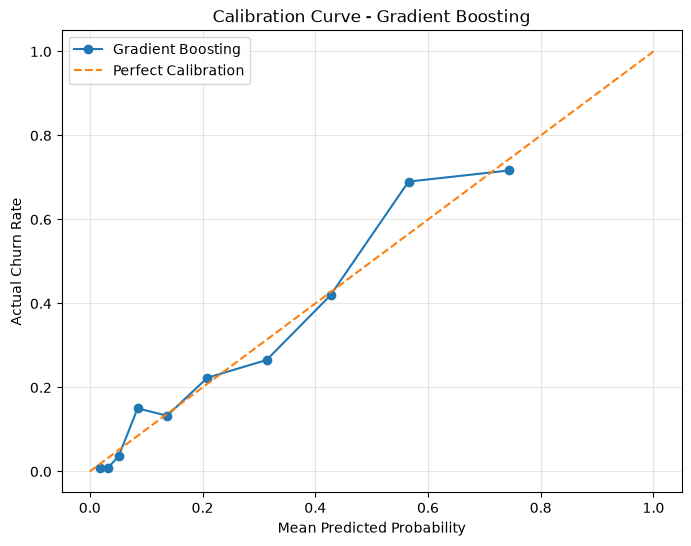

In [144]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_val,
    y_gb_val_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Gradient Boosting"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Churn Rate")
plt.title("Calibration Curve - Gradient Boosting")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [145]:
calibration_comparison = pd.DataFrame({
    "Mean_Predicted": prob_pred,
    "Actual_Rate": prob_true
})

calibration_comparison["Gap"] = (
    calibration_comparison["Actual_Rate"]
    - calibration_comparison["Mean_Predicted"]
)

print(calibration_comparison.round(3))

   Mean_Predicted  Actual_Rate    Gap
0           0.019        0.009 -0.010
1           0.032        0.009 -0.024
2           0.051        0.037 -0.014
3           0.085        0.150  0.066
4           0.137        0.133 -0.004
5           0.209        0.223  0.015
6           0.314        0.265 -0.048
7           0.427        0.420 -0.007
8           0.566        0.690  0.125
9           0.744        0.717 -0.027


In [146]:
from sklearn.calibration import CalibratedClassifierCV

# Sigmoid Calibration
gb_sigmoid = CalibratedClassifierCV(
    estimator=gb_model,
    method="sigmoid",
    cv=5
)

# Isotonic Calibration
gb_isotonic = CalibratedClassifierCV(
    estimator=gb_model,
    method="isotonic",
    cv=5
)

# Fit on training subset
gb_sigmoid.fit(X_fit, y_fit)
gb_isotonic.fit(X_fit, y_fit)

print("Calibration models fitted successfully.")

Calibration models fitted successfully.


In [147]:
# Original model
gb_original_proba = gb_model.predict_proba(X_val)[:, 1]

# Calibrated models
gb_sigmoid_proba = gb_sigmoid.predict_proba(X_val)[:, 1]
gb_isotonic_proba = gb_isotonic.predict_proba(X_val)[:, 1]

print("Original:", gb_original_proba[:5])
print("Sigmoid:", gb_sigmoid_proba[:5])
print("Isotonic:", gb_isotonic_proba[:5])

Original: [0.27098019 0.0298661  0.03964736 0.13138345 0.22047667]
Sigmoid: [0.26305979 0.02968888 0.04261691 0.13007938 0.22783896]
Isotonic: [0.26717892 0.01454734 0.03568643 0.14440013 0.24106342]


In [148]:
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

calibration_comparison = pd.DataFrame({
    "Model": ["Original", "Sigmoid", "Isotonic"],
    "Brier Score": [
        brier_score_loss(y_val, gb_original_proba),
        brier_score_loss(y_val, gb_sigmoid_proba),
        brier_score_loss(y_val, gb_isotonic_proba)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, gb_original_proba),
        roc_auc_score(y_val, gb_sigmoid_proba),
        roc_auc_score(y_val, gb_isotonic_proba)
    ],
    "PR-AUC": [
        average_precision_score(y_val, gb_original_proba),
        average_precision_score(y_val, gb_sigmoid_proba),
        average_precision_score(y_val, gb_isotonic_proba)
    ]
})

print(calibration_comparison.round(4))

      Model  Brier Score  ROC-AUC  PR-AUC
0  Original       0.1328   0.8510  0.6707
1   Sigmoid       0.1327   0.8514  0.6688
2  Isotonic       0.1332   0.8500  0.6676


In [149]:
from sklearn.calibration import calibration_curve

models_proba = {
    "Original": gb_original_proba,
    "Sigmoid": gb_sigmoid_proba,
    "Isotonic": gb_isotonic_proba
}

for name, probabilities in models_proba.items():

    prob_true, prob_pred = calibration_curve(
        y_val,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    mean_gap = abs(prob_true - prob_pred).mean()

    print(f"{name} Mean Absolute Calibration Gap: {mean_gap:.4f}")

Original Mean Absolute Calibration Gap: 0.0340
Sigmoid Mean Absolute Calibration Gap: 0.0391
Isotonic Mean Absolute Calibration Gap: 0.0314


In [151]:
# Final model selection

final_model = gb_model
final_threshold = 0.4

final_model_name = "Gradient Boosting"

final_validation_predictions = (
    final_model.predict_proba(X_val)[:, 1]
    >= final_threshold
).astype(int)

print("Final Model:", final_model_name)
print("Decision Threshold:", final_threshold)
print(
    "Validation F1-score:",
    round(f1_score(y_val, final_validation_predictions), 4)
)

Final Model: Gradient Boosting
Decision Threshold: 0.4
Validation F1-score: 0.6492


In [152]:
try:
    import shap
    print("SHAP version:", shap.__version__)

except ImportError:
    print("SHAP is not installed.")

SHAP is not installed.


In [153]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 428.3 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 428.3 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 428.3 kB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 412.1 kB/s  0:00:02

   -------------------------- -----

In [154]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [155]:
# Extract the fitted preprocessor and classifier
preprocessor = final_model.named_steps["preprocessor"]
classifier = final_model.named_steps["classifier"]

# Transform validation data
X_val_transformed = preprocessor.transform(X_val)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Transformed data shape:", X_val_transformed.shape)
print("Number of feature names:", len(feature_names))
print("Classifier:", type(classifier).__name__)

Transformed data shape: (1127, 46)
Number of feature names: 46
Classifier: GradientBoostingClassifier


In [157]:
import numpy as np

# Select a sample for SHAP analysis
X_shap = X_val_transformed[:200]

# Create SHAP explainer
explainer = shap.TreeExplainer(classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values shape:", np.array(shap_values).shape)

SHAP values shape: (200, 46)


In [158]:
# Calculate mean absolute SHAP values
mean_shap_values = np.abs(shap_values).mean(axis=0)

# Create feature importance DataFrame
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": mean_shap_values
})

# Sort features by importance
shap_importance = shap_importance.sort_values(
    by="Mean_SHAP",
    ascending=False
)

display(shap_importance.head(15))

,Feature,Mean_SHAP
37,cat__Contract_Month-to-month,0.493521
0,num__tenure,0.378090
17,cat__InternetService_Fiber optic,0.271541
39,cat__Contract_Two year,0.197676
19,cat__OnlineSecurity_No,0.194583
1,num__MonthlyCharges,0.178292
28,cat__TechSupport_No,0.172237
2,num__TotalCharges,0.145205
13,cat__MultipleLines_No,0.133535
44,cat__PaymentMethod_Electronic check,0.123440


In [159]:
# Convert SHAP values to a DataFrame
shap_values_df = pd.DataFrame(
    shap_values,
    columns=feature_names
)

# Select important features
top_features = shap_importance["Feature"].head(10)

# Calculate mean SHAP direction
shap_direction = pd.DataFrame({
    "Feature": top_features,
    "Mean_SHAP": [
        shap_values_df[feature].mean()
        for feature in top_features
    ],
    "Mean_Absolute_SHAP": [
        shap_values_df[feature].abs().mean()
        for feature in top_features
    ]
})

display(shap_direction)

,Feature,Mean_SHAP,Mean_Absolute_SHAP
37,cat__Contract_Month-to-month,0.047903,0.493521
0,num__tenure,-0.085446,0.378090
17,cat__InternetService_Fiber optic,-0.002717,0.271541
39,cat__Contract_Two year,0.019555,0.197676
19,cat__OnlineSecurity_No,0.004446,0.194583
1,num__MonthlyCharges,0.038853,0.178292
28,cat__TechSupport_No,0.005555,0.172237
2,num__TotalCharges,0.070159,0.145205
13,cat__MultipleLines_No,-0.040932,0.133535
44,cat__PaymentMethod_Electronic check,0.000634,0.123440


In [160]:
shap_distribution = pd.DataFrame({
    "Feature": top_features,
    "Mean_SHAP": shap_values_df[top_features].mean().values,
    "Std_SHAP": shap_values_df[top_features].std().values,
    "Min_SHAP": shap_values_df[top_features].min().values,
    "Max_SHAP": shap_values_df[top_features].max().values
})

display(shap_distribution.round(4))

,Feature,Mean_SHAP,Std_SHAP,Min_SHAP,Max_SHAP
37,cat__Contract_Month-to-month,0.0479,0.4957,-0.6355,0.5408
0,num__tenure,-0.0854,0.4469,-1.0005,1.1351
17,cat__InternetService_Fiber optic,-0.0027,0.2794,-0.3357,0.3548
39,cat__Contract_Two year,0.0196,0.2249,-0.4361,0.1724
19,cat__OnlineSecurity_No,0.0044,0.1983,-0.2905,0.2423
1,num__MonthlyCharges,0.0389,0.2276,-0.4708,0.6282
28,cat__TechSupport_No,0.0056,0.1751,-0.2925,0.2471
2,num__TotalCharges,0.0702,0.1676,-0.1135,0.6556
13,cat__MultipleLines_No,-0.0409,0.1494,-0.3320,0.2495
44,cat__PaymentMethod_Electronic check,0.0006,0.1351,-0.1206,0.2518


In [161]:
tenure_analysis = pd.DataFrame({
    "Tenure": X_val.iloc[:200]["tenure"].values,
    "SHAP_Tenure": shap_values_df["num__tenure"].values
})

tenure_analysis["Tenure_Group"] = pd.cut(
    tenure_analysis["Tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

tenure_summary = (
    tenure_analysis
    .groupby("Tenure_Group", observed=False)
    .agg(
        Customer_Count=("SHAP_Tenure", "count"),
        Mean_SHAP=("SHAP_Tenure", "mean"),
        Mean_Absolute_SHAP=("SHAP_Tenure", lambda x: x.abs().mean())
    )
    .reset_index()
)

display(tenure_summary.round(4))

,Tenure_Group,Customer_Count,Mean_SHAP,Mean_Absolute_SHAP
0,0-12,64,0.4316,0.4552
1,13-24,27,-0.0528,0.1186
2,25-48,54,-0.2838,0.2838
3,49-72,55,-0.5084,0.5084


In [162]:
tenure_contract_analysis = pd.DataFrame({
    "Tenure": X_val.iloc[:200]["tenure"].values,
    "Contract": X_val.iloc[:200]["Contract"].values,
    "SHAP_Tenure": shap_values_df["num__tenure"].values
})

tenure_contract_summary = (
    tenure_contract_analysis
    .groupby("Contract", observed=False)
    .agg(
        Customer_Count=("SHAP_Tenure", "count"),
        Mean_SHAP=("SHAP_Tenure", "mean"),
        Mean_Absolute_SHAP=("SHAP_Tenure", lambda x: x.abs().mean())
    )
    .reset_index()
)

display(tenure_contract_summary.round(4))

,Contract,Customer_Count,Mean_SHAP,Mean_Absolute_SHAP
0,Month-to-month,115,0.1196,0.3787
1,One year,40,-0.2824,0.3132
2,Two year,45,-0.4342,0.4342


In [163]:
contract_features = [
    "cat__Contract_Month-to-month",
    "cat__Contract_One year",
    "cat__Contract_Two year"
]

contract_shap_summary = pd.DataFrame({
    "Feature": contract_features,
    "Mean_SHAP": [
        shap_values_df[col].mean()
        for col in contract_features
    ],
    "Mean_Absolute_SHAP": [
        shap_values_df[col].abs().mean()
        for col in contract_features
    ]
})

display(contract_shap_summary.round(4))

,Feature,Mean_SHAP,Mean_Absolute_SHAP
0,cat__Contract_Month-to-month,0.0479,0.4935
1,cat__Contract_One year,-0.0061,0.0237
2,cat__Contract_Two year,0.0196,0.1977


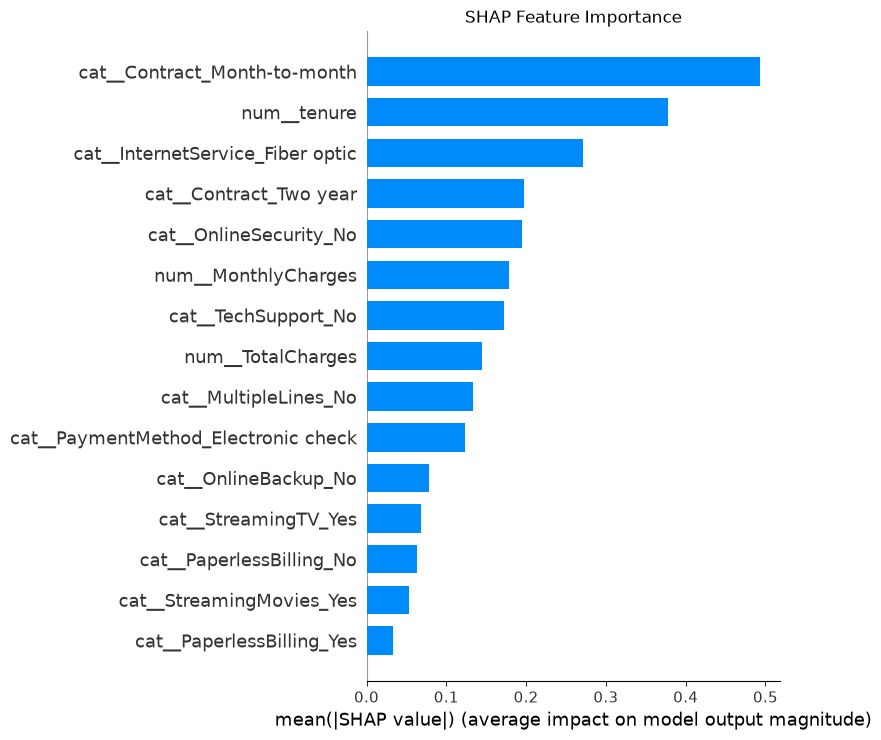

In [164]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create output directory
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Plot SHAP feature importance
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

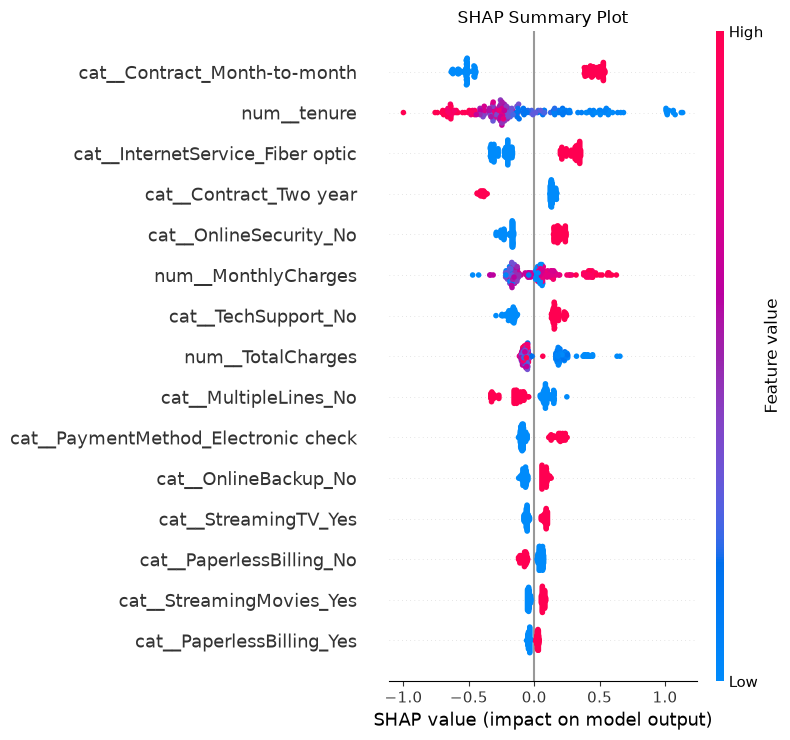

In [165]:
plt.figure(figsize=(11, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot")
plt.tight_layout()

plt.savefig(
    figures_dir / "shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

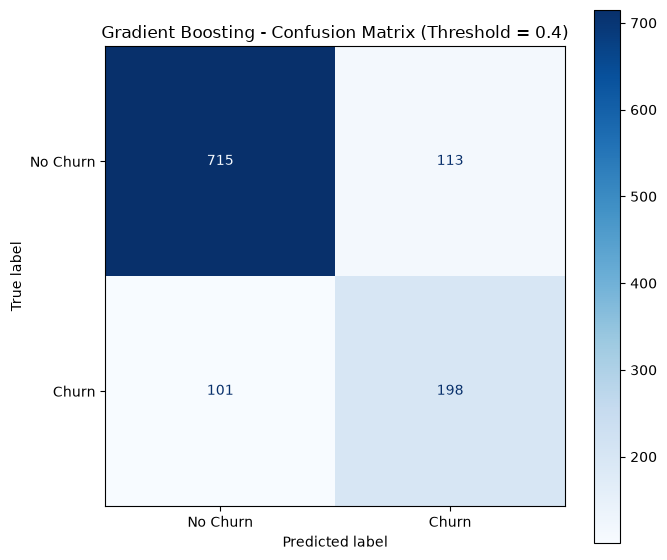

In [166]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(
    y_val,
    final_validation_predictions
)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Gradient Boosting - Confusion Matrix (Threshold = 0.4)")
plt.tight_layout()

plt.savefig(
    figures_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()